# Gaming & Mental Health — EDA

**Dataset:** Online Gaming Anxiety Data (Kaggle). A survey answered by about 13,464 gamers.
**Scientific source:** Sauter & Draschkow (2017), *Are Gamers Sad and Isolated?*

### Questions
1. Which age groups are most addicted, and does it differ between genders?
2. Does addiction differ by work status and education level?
3. Do addicted gamers have higher anxiety, lower life satisfaction and higher social phobia?
4. Is the relationship between gaming hours and mental health strong?
5. Does the reason for playing (whyplay) affect anxiety?
6. Is playing with friends better than playing alone?

## Data Loading & Structure

In [226]:
import pandas as pd
import numpy as np
import kagglehub
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

In [227]:
df = pd.read_csv("GamingStudy_data.csv", encoding="ISO-8859-1", low_memory=False)

I used **encoding="ISO-8859-1** because when I first read the file I got a **UnicodeDecodeError**. The file has some special characters that are not UTF-8.
I also used **low_memory=False** so pandas reads each column fully before deciding its type, because some columns mix numbers and text.

**Column Description**

 S. No.: Serial number

Timestamp: Time the participant filled in the survey

GAD1 – GAD7: Anxiety scale questions (Generalized Anxiety Disorder), each from 0 to 3

GAD_T: Total anxiety score (0–21)

GADE: How difficult these problems made the person's work or life

SWL1 – SWL5:Satisfaction With Life questions, each from 1 to 7

SWL_T: Total life satisfaction score (5–35)

Game: Name of the game

Platform: Platform (PC, Console, Smartphone)

Hours: Gaming hours per week

earnings: Whether the player earns money from the game

whyplay: Reason for playing

League, highestleague: Rank in the game

streams: Hours per week spent watching streams

SPIN1 – SPIN17: Social Phobia Inventory questions, each from 0 to 4

SPIN_T: Total social phobia score (0–68)

Narcissism: Narcissism scale (1–5)
Gender, Age: Gender and age

Work: Work status

Degree: Highest degree attained

Birthplace, Residence (+ _ISO3): Country of birth and country of residence

Reference: Where the participant found the survey

Playstyle: Playstyle (single player, with friends, with strangers)

accept:Accepted the terms and conditions



In [228]:
df.head()

,S. No.,Timestamp,GAD1,GAD2,GAD3,GAD4,GAD5,GAD6,GAD7,GADE,SWL1,SWL2,SWL3,SWL4,SWL5,Game,Platform,Hours,earnings,whyplay,League,highestleague,streams,SPIN1,SPIN2,SPIN3,SPIN4,SPIN5,SPIN6,SPIN7,SPIN8,SPIN9,SPIN10,SPIN11,SPIN12,SPIN13,SPIN14,SPIN15,SPIN16,SPIN17,Narcissism,Gender,Age,Work,Degree,Birthplace,Residence,Reference,Playstyle,accept,GAD_T,SWL_T,SPIN_T,Residence_ISO3,Birthplace_ISO3
0,1,42052.00437,0,0,0,0,1,0,0,Not difficult at all,3,5,5,5,5,Skyrim,"Console (PS, Xbox, ...)",15.0,I play for fun,having fun,NaN,NaN,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,Male,25,Unemployed / between jobs,Bachelor (or equivalent),USA,USA,Reddit,Singleplayer,Accept,1,23,5.0,USA,USA
1,2,42052.00680,1,2,2,2,0,1,0,Somewhat difficult,3,5,2,5,1,Other,PC,8.0,I play for fun,having fun,NaN,NaN,2.0,2.0,1.0,1.0,3.0,2.0,3.0,1.0,3.0,4.0,0.0,3.0,0.0,1.0,3.0,3.0,1.0,2.0,1.0,Male,41,Unemployed / between jobs,Bachelor (or equivalent),USA,USA,Reddit,Multiplayer - online - with strangers,Accept,8,16,33.0,USA,USA
2,3,42052.03860,0,2,2,0,0,3,1,Not difficult at all,2,6,5,2,2,Other,PC,0.0,I play for fun,having fun,NaN,NaN,0.0,1.0,0.0,1.0,2.0,3.0,4.0,2.0,1.0,0.0,1.0,1.0,3.0,0.0,2.0,4.0,4.0,2.0,4.0,Female,32,Employed,Bachelor (or equivalent),Germany,Germany,Reddit,Singleplayer,Accept,8,17,31.0,DEU,DEU
3,4,42052.06804,0,0,0,0,0,0,0,Not difficult at all,2,5,5,3,2,Other,PC,20.0,I play for fun,improving,NaN,NaN,5.0,2.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,1.0,0.0,0.0,2.0,Male,28,Employed,Bachelor (or equivalent),USA,USA,Reddit,Multiplayer - online - with online acquaintanc...,Accept,0,17,11.0,USA,USA
4,5,42052.08948,2,1,2,2,2,3,2,Very difficult,2,2,4,5,1,Other,"Console (PS, Xbox, ...)",20.0,I play for fun,having fun,NaN,NaN,1.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,3.0,0.0,1.0,Male,19,Employed,High school diploma (or equivalent),USA,South Korea,Reddit,Multiplayer - online - with strangers,Accept,14,14,13.0,KOR,USA


In [229]:
df.shape

(13464, 55)

In [230]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13464 entries, 0 to 13463
Data columns (total 55 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   S. No.           13464 non-null  int64  
 1   Timestamp        13464 non-null  float64
 2   GAD1             13464 non-null  int64  
 3   GAD2             13464 non-null  int64  
 4   GAD3             13464 non-null  int64  
 5   GAD4             13464 non-null  int64  
 6   GAD5             13464 non-null  int64  
 7   GAD6             13464 non-null  int64  
 8   GAD7             13464 non-null  int64  
 9   GADE             12815 non-null  object 
 10  SWL1             13464 non-null  int64  
 11  SWL2             13464 non-null  int64  
 12  SWL3             13464 non-null  int64  
 13  SWL4             13464 non-null  int64  
 14  SWL5             13464 non-null  int64  
 15  Game             13464 non-null  object 
 16  Platform         13464 non-null  object 
 17  Hours       

In [231]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
S. No.,13464.0,7096.839201,4114.478220,1.00000,3532.750000,7087.500000,10654.250000,14250.00000
Timestamp,13464.0,42054.841222,0.272948,42052.00437,42054.716548,42054.800675,42054.932112,42058.36375
GAD1,13464.0,0.860963,0.926542,0.00000,0.000000,1.000000,1.000000,3.00000
GAD2,13464.0,0.673351,0.915724,0.00000,0.000000,0.000000,1.000000,3.00000
GAD3,13464.0,0.965761,0.982776,0.00000,0.000000,1.000000,2.000000,3.00000
GAD4,13464.0,0.724079,0.921971,0.00000,0.000000,0.000000,1.000000,3.00000
GAD5,13464.0,0.488042,0.837014,0.00000,0.000000,0.000000,1.000000,3.00000
GAD6,13464.0,0.911022,0.931168,0.00000,0.000000,1.000000,1.000000,3.00000
GAD7,13464.0,0.588755,0.894408,0.00000,0.000000,0.000000,1.000000,3.00000
SWL1,13464.0,3.720440,1.736264,1.00000,2.000000,4.000000,5.000000,7.00000


**What I noticed from describe():**
- The max of **Hours** is **8000** and the max of **streams** is **9001**, but a week only has **168 hours**. So there are impossible values
- The **std** of **Hours** (70) is much bigger than the mean (22), which is another sign of extreme values.
- The minimum age is 18 because the survey only allowed people 18+.

In [232]:
(df.isnull().mean() * 100).round(2).sort_values(ascending=False)


,0
highestleague,100.00
League,13.76
Degree,11.71
SPIN_T,4.83
GADE,4.82
accept,3.07
SPIN13,1.39
SPIN11,1.39
SPIN17,1.30
SPIN12,1.25



- Very high (like **highestleague** 100%) → drop the column.
- Small (less than 5%) → drop the rows.
- Medium → fill it, depending on the column.

In [233]:
df.duplicated().sum()

np.int64(0)



## Data Cleaning

In [234]:
for col in ["Platform","Game","League"]:
   print(df[col].value_counts(normalize=True),'\n')


Platform
PC                         0.981803
Console (PS, Xbox, ...)    0.016488
Smartphone / Tablet        0.001708
Name: proportion, dtype: float64 

Game
League of Legends      0.840315
Other                  0.075832
Starcraft 2            0.025624
Counter Strike         0.023619
World of Warcraft      0.011289
Hearthstone            0.007501
Diablo 3               0.006610
Heroes of the Storm    0.003045
Guild Wars 2           0.002748
Skyrim                 0.002080
Destiny                0.001337
Name: proportion, dtype: float64 

League
Gold                                                                                                                             0.083534
Silver                                                                                                                           0.055977
Platinum                                                                                                                         0.054685
Diamond                            

In [235]:
columns_to_drop = ['S. No.', 'Timestamp', 'GAD1', 'GAD2', 'GAD3', 'GAD4', 'GAD5', 'GAD6', 'GAD7','Platform',
                   'SWL1', 'SWL2', 'SWL3', 'SWL4', 'SWL5','SPIN1', 'SPIN2', 'SPIN3', 'SPIN4', 'SPIN5',
                   'SPIN6', 'SPIN7', 'SPIN8', 'SPIN9','SPIN10', 'SPIN11', 'SPIN12', 'SPIN13', 'SPIN14',
                   'SPIN15', 'SPIN16', 'SPIN17','League', 'highestleague', 'Narcissism', 'Game',
                   'Birthplace', 'Residence', 'Birthplace_ISO3', 'Residence_ISO3','Reference', 'accept']

df = df.drop(columns=columns_to_drop)
df.shape

(13464, 13)

I dropped these columns because:

- **GAD1-7, SWL1-5, SPIN1-17**: we already have their totals in GAD_T, SWL_T and SPIN_T.

- **S. No., Timestamp, Reference, accept, Birthplace, Residence, Birthplace_ISO3 and Residence_ISO3**: they are not related to my questions.

- **highestleague** is 100% empty, and **League** is 13.8% empty and written as free text with 1,454 different answers written in different ways (Gold, gold, Bronze 3 :( ...), so I can't use it.

- **Platform** and **Game**: almost everyone has the same value (98% play on PC and 84% play League of Legends), so they don't help compare players.

- **Narcissism**: it is not part of my questions.

In [236]:
(df.isnull().mean() * 100).round(2).sort_values(ascending=False)

,0
Degree,11.71
SPIN_T,4.83
GADE,4.82
streams,0.74
Work,0.28
Hours,0.22
earnings,0.00
whyplay,0.00
Age,0.00
Gender,0.00


After dropping the columns, only 6 columns still have missing values. I handle each one separately below.

### Missing values: GADE
**GADE** is the question after the anxiety questions in the survey: *"If you checked off any problems, how difficult have these made it for you to do your work, take care of things at home, or get along with other people?"*. It was optional.


In [237]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13464 entries, 0 to 13463
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   GADE       12815 non-null  object 
 1   Hours      13434 non-null  float64
 2   earnings   13464 non-null  object 
 3   whyplay    13464 non-null  object 
 4   streams    13364 non-null  float64
 5   Gender     13464 non-null  object 
 6   Age        13464 non-null  int64  
 7   Work       13426 non-null  object 
 8   Degree     11887 non-null  object 
 9   Playstyle  13464 non-null  object 
 10  GAD_T      13464 non-null  int64  
 11  SWL_T      13464 non-null  int64  
 12  SPIN_T     12814 non-null  float64
dtypes: float64(3), int64(3), object(7)
memory usage: 1.3+ MB


In [238]:
df[df['GADE'].isnull()]['GAD_T'].value_counts()

,count
GAD_T,
0,595
1,20
2,11
3,5
7,4
4,3
15,2
11,2
12,2


Most of the people who left **GADE** empty  (595 out of 649) have an anxiety score of **0**. (649 = 13,464 − 12,815 non-null values). This makes sense, because the question starts with "If you checked off any problems", so people with no anxiety skipped it.

In [239]:
df[df['GAD_T'] == 0]['GADE'].value_counts()

,count
GADE,
Not difficult at all,1031
Somewhat difficult,38
Very difficult,4
Extremely difficult,1


Then I checked what people with 0 anxiety chose when they **did** answer: almost all of them (1,031 out of 1,074 , about 96% ) chose *Not difficult at all*.

In [240]:
df['GADE'] = df['GADE'].fillna('Not difficult at all')

So the missing values in **GADE** are not random. They most likely mean "no difficulty", so I filled them with **Not difficult at all** instead of dropping 649 rows.

### Missing values: Degree

In [241]:
df['Degree'].value_counts()

,count
Degree,
High school diploma (or equivalent),8560
Bachelor (or equivalent),2687
Master (or equivalent),546
"Ph.D., Psy. D., MD (or equivalent)",94


The survey had 5 options for Degree: **None**, High school, Bachelor, Master and PhD. But here I only see 4, and **None** is missing.

In [242]:
pd.read_csv("GamingStudy_data.csv", encoding="ISO-8859-1", low_memory=False,
            keep_default_na=False)['Degree'].value_counts()

,count
Degree,
High school diploma (or equivalent),8560
Bachelor (or equivalent),2687
None,1577
Master (or equivalent),546
"Ph.D., Psy. D., MD (or equivalent)",94


When I read the file again with **keep_default_na=False**, the **None** option appears with 1,577 people. This is the same number as the missing values in Degree.
So pandas was reading the word "None" as a missing value (NaN) by default. These people are not missing, they just don't have a degree.

In [243]:
df['Degree'].isnull().sum()

np.int64(1577)

In [244]:
df['Degree'] = df['Degree'].fillna('None')
df['Degree'].value_counts()

,count
Degree,
High school diploma (or equivalent),8560
Bachelor (or equivalent),2687
None,1577
Master (or equivalent),546
"Ph.D., Psy. D., MD (or equivalent)",94


I filled the missing Degree values back with **None**, so now all 5 options from the survey are there.

### Missing values: the rest

In [245]:
(df.isnull().mean() * 100).round(2).sort_values(ascending=False)

,0
SPIN_T,4.83
streams,0.74
Work,0.28
Hours,0.22
GADE,0.00
whyplay,0.00
earnings,0.00
Age,0.00
Gender,0.00
Degree,0.00


In [246]:
df = df.dropna()
df.isnull().sum()

,0
GADE,0
Hours,0
earnings,0
whyplay,0
streams,0
Gender,0
Age,0
Work,0
Degree,0
Playstyle,0


The remaining missing values are in **SPIN_T** (4.8%), **streams** (0.7%), **Work** (0.3%) and **Hours** (0.2%). These are small percentages, so I dropped the rows.
I didn't fill **SPIN_T** with the mean because social phobia is one of the things I'm studying, and filling it would add fake results. **Hours** is what I use to define addiction, so it has to be the real value.

In [247]:
df.shape

(12671, 13)

In [248]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours,12671.0,22.175124,72.266861,0.0,12.0,20.0,28.0,8000.0
streams,12671.0,11.284903,80.633826,0.0,4.0,8.0,15.0,9001.0
Age,12671.0,20.969616,3.310376,18.0,18.0,20.0,22.0,56.0
GAD_T,12671.0,5.192329,4.694842,0.0,2.0,4.0,8.0,21.0
SWL_T,12671.0,19.803094,7.227074,5.0,14.0,20.0,26.0,35.0
SPIN_T,12671.0,19.815800,13.439619,0.0,9.0,17.0,28.0,68.0


### Wrong values
Even after handling missing values, **describe**() still shows the 8000 and 9001 values.

In [249]:
df[df['Hours'] > 168]

,GADE,Hours,earnings,whyplay,streams,Gender,Age,Work,Degree,Playstyle,GAD_T,SWL_T,SPIN_T
3860,Very difficult,8000.0,I earn a living by playing this game,winning,9001.0,Other,18,Unemployed / between jobs,"Ph.D., Psy. D., MD (or equivalent)",Singleplayer,2,12,68.0
9435,Not difficult at all,420.0,for my ear,my ear is happy,420.0,Other,42,Employed,"Ph.D., Psy. D., MD (or equivalent)",with my ear,0,5,0.0


In [250]:
df = df[df['Hours'] <= 168]
df = df[df['streams'] <= 168]
df.shape

(12668, 13)

These two players were clearly not answering seriously:
- The first one wrote 8000 hours a week, 9001 hours of streams, and says they are 18 years old with a PhD.
- The second one wrote 420 hours and answers like "for my ear" and "my ear is happy".

If someone is joking in one answer, their other answers can't be trusted either, so I removed the whole row that has any **Hours** or **streams** value above **168**, because that's the total number of hours in a week (7 × 24). Only 3 rows were removed.

### Standardizing text

In [251]:
for col in ["GADE","earnings","whyplay","Gender","Work","Degree"]:
     print(df[col].value_counts(),'\n')

GADE
Not difficult at all    6497
Somewhat difficult      4824
Very difficult           965
Extremely difficult      382
Name: count, dtype: int64 

earnings
I play for fun                                                                                           11415
I play mostly for fun but earn a little on the side (tournament winnings, streaming, etc)                  917
I earn a living by playing this game                                                                        45
I play to win                                                                                                3
i try                                                                                                        2
                                                                                                         ...  
I Play for fun and working on making earn out of it.                                                         1
I play ranked mostly                                             

**whyplay**, **earnings** and **Playstyle** have hundreds of free-text answers, because the survey had an "Other" option where people could write anything. Most of them appear only once or twice.

In [252]:
for col in ["whyplay", "Playstyle", "earnings"]:
    df[col] = df[col].str.strip().str.lower()

for col in ["whyplay", "Playstyle", "earnings"]:
    counts = df[col].value_counts()
    rare = counts[counts < 30].index
    df[col] = df[col].replace(rare, "other")
    print(df[col].value_counts(), "\n")

whyplay
having fun          5019
improving           4630
winning             1953
relaxing             612
other                406
all of the above      48
Name: count, dtype: int64 

Playstyle
multiplayer - online - with real life friends                    5241
multiplayer - online - with strangers                            3884
multiplayer - online - with online acquaintances or teammates    2496
singleplayer                                                      720
other                                                             281
multiplayer - offline (people in the same room)                    46
Name: count, dtype: int64 

earnings
i play for fun                                                                               11415
i play mostly for fun but earn a little on the side (tournament winnings, streaming, etc)      917
other                                                                                          291
i earn a living by playing this game              

In [253]:
df['Playstyle'] = df['Playstyle'].replace({
    'multiplayer - online - with real life friends': 'Real friends',
    'multiplayer - online - with strangers': 'Strangers',
    'multiplayer - online - with online acquaintances or teammates': 'Online friends',
    'multiplayer - offline (people in the same room)': 'Offline (same room)',
    'singleplayer': 'Singleplayer'})

df['Playstyle'].value_counts()

,count
Playstyle,
Real friends,5241
Strangers,3884
Online friends,2496
Singleplayer,720
other,281
Offline (same room),46


- **str.strip**() removes extra spaces and **str.lower()** makes everything lowercase, so "All of the above" and "all of the above" become the same answer.
- Then any answer with fewer than **30** people goes into **other**. I chose 30 because a group smaller than that is too small to compare averages reliably.

In [254]:
orig = pd.read_csv("GamingStudy_data.csv", encoding="ISO-8859-1", low_memory=False)

I loaded the original data again as **orig** so I can compare the addiction rate before and after cleaning later.

### Renaming columns

In [255]:
df = df.rename(columns={'GAD_T': 'Anxiety',
                        'SWL_T': 'Life_Satisfaction',
                        'SPIN_T': 'Social_Phobia',
                        'GADE': 'Anxiety_Impact'})
df.columns

Index(['Anxiety_Impact', 'Hours', 'earnings', 'whyplay', 'streams', 'Gender',
       'Age', 'Work', 'Degree', 'Playstyle', 'Anxiety', 'Life_Satisfaction',
       'Social_Phobia'],
      dtype='object')



### New columns

In [256]:
df['is_addicted'] = df['Hours'] >= 40
df['is_addicted'].value_counts(normalize=True) * 100

,proportion
is_addicted,
False,88.869593
True,11.130407


I defined an **addicted** player as someone who plays **40 hours or more per week**, because 40 hours is the same as a full-time job (8 hours × 5 days). About 11% of the players are in this group.


In [257]:
df['Age'].value_counts()

,count
Age,
18,3321
19,2021
20,1749
21,1416
22,1074
23,826
24,628
25,502
26,326


In [258]:
df['age_group'] = pd.cut(df['Age'], bins=[17, 20, 25, 30, 100],
                         labels=['18-20', '21-25', '26-30', '31+'])
df['age_group'].value_counts()

,count
age_group,
18-20,7091
21-25,4446
26-30,898
31+,233


Most players are 18-25, and after 30 there are very few people in each age, so I grouped the ages (binning) so I can compare age groups.

In [259]:
print('Before cleaning:', (orig['Hours'] >= 40).mean() * 100)
print('After cleaning:', df['is_addicted'].mean() * 100)

Before cleaning: 11.326500297088533
After cleaning: 11.13040732554468


The addiction rate only changed from 11.33% to 11.13%, so the rows I removed were not mostly addicted players, and my cleaning didn’t create bias



In [260]:
df.to_csv("clean_data.csv", index=False)




## Univariate Analysis

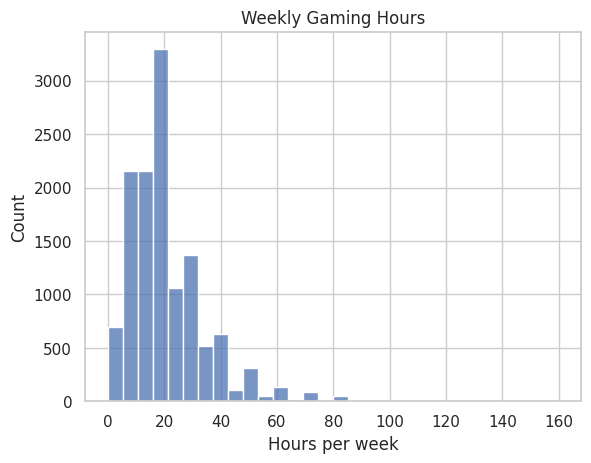

In [261]:
sns.histplot(df['Hours'], bins=30)
plt.title('Weekly Gaming Hours')
plt.xlabel('Hours per week')
plt.show()

In [262]:
print('Mean:', df['Hours'].mean())
print('Median:', df['Hours'].median())
print('Skewed:', df['Hours'].skew())

Mean: 21.507814966845594
Median: 20.0
Skewed: 1.8573708213482607



Most players play between 10 and 30 hours a week. The mean (21.5) is a bit higher than the median (20), so the data is right skewed.

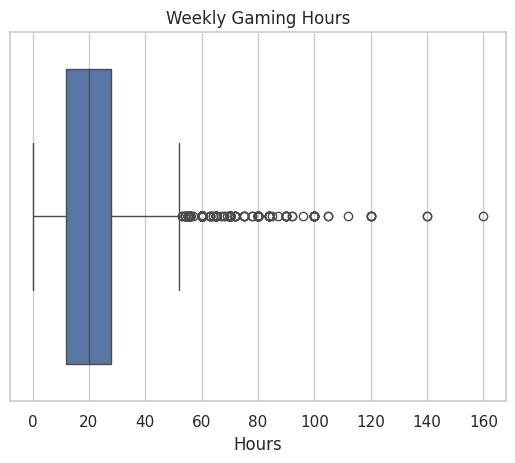

In [263]:
sns.boxplot(x=df['Hours'])
plt.title('Weekly Gaming Hours')
plt.show()

In [264]:
Q1 = df['Hours'].quantile(0.25)
Q3 = df['Hours'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print('Upper limit:', upper)
print('Number of outliers:', (df['Hours'] > upper).sum())

Upper limit: 52.0
Number of outliers: 375



Using the IQR rule, anything above 52 hours counts as an outlier. I decided not to remove these players because 52+ hours is possible in real life, and these are exactly the heavy gamers I want to study. I only removed the impossible values (more than 168 hours, which is the whole week).

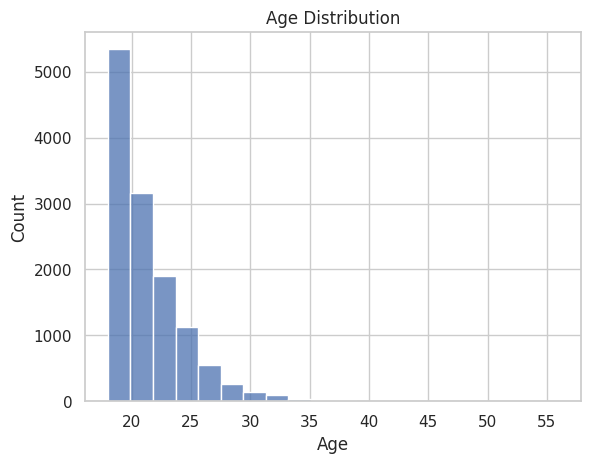

In [265]:
sns.histplot(df['Age'], bins=20)
plt.title('Age Distribution')
plt.show()

In [266]:
print('Youngest player:', df['Age'].min())
print('Players 31+:', (df['Age'] > 30).sum())
print('Oldest player:', df['Age'].max())

Youngest player: 18
Players 31+: 233
Oldest player: 56



The players are very young. Most of them are between 18 and 25, and the number drops fast after that. This makes sense because the survey was shared on Reddit and gaming websites, and only people 18+ were allowed to take it.

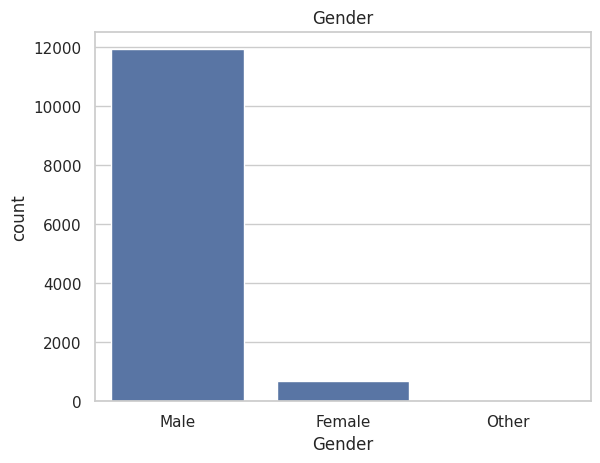

In [267]:
sns.countplot(x='Gender', data=df)
plt.title('Gender')
plt.show()

In [268]:
df['Gender'].value_counts(normalize=True) * 100

,proportion
Gender,
Male,94.197979
Female,5.431007
Other,0.371014



94% of the players are male and only about 5% are female.

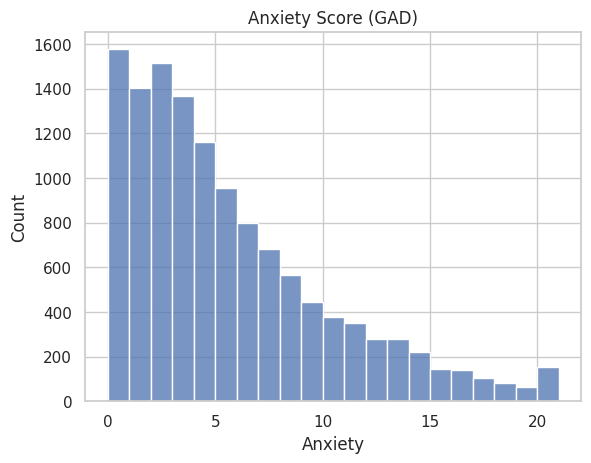

In [269]:
sns.histplot(df['Anxiety'], bins=21)
plt.title('Anxiety Score (GAD)')
plt.show()

In [270]:
print('Mean:', df['Anxiety'].mean())
print('Median:', df['Anxiety'].median())
print('Skewed:', df['Anxiety'].skew())


Mean: 5.192611304073256
Median: 4.0
Skewed: 1.1696367611877594


In [271]:
(df['Anxiety'] >= 5).mean() * 100

np.float64(44.55320492579729)

In [272]:
(df['Anxiety'] <= 5).mean() * 100

np.float64(63.00126302494474)


Most players have low anxiety scores (0 to 5), and fewer players have high scores. So anxiety is also right skewed. Most gamers in this survey are not very anxious, but there is a group with high anxiety.

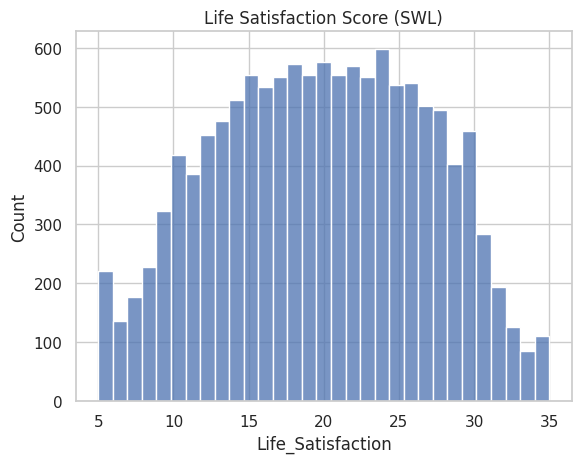

In [273]:
sns.histplot(df['Life_Satisfaction'], bins=31)
plt.title('Life Satisfaction Score (SWL)')
plt.show()

In [274]:
print('Mean:', df['Life_Satisfaction'].mean())
print('Median:', df['Life_Satisfaction'].median())
print('Skewed:', df['Life_Satisfaction'].skew())

Mean: 19.805809914745815
Median: 20.0
Skewed: -0.05422313471665184


**Life satisfaction** is almost symmetric. The mean (19.8) and the median (20) are very close and the skewness is about 0, so players are spread evenly around the middle of the scale. About half of them are below 20 (the neutral point).



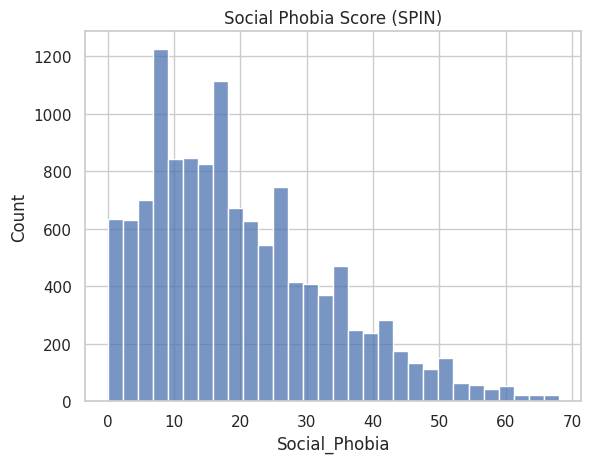

In [275]:
sns.histplot(df['Social_Phobia'], bins=30)
plt.title('Social Phobia Score (SPIN)')
plt.show()

In [276]:
print('Mean:', df['Social_Phobia'].mean())
print('Median:', df['Social_Phobia'].median())
print('Skewed:', df['Social_Phobia'].skew())

Mean: 19.813467003473317
Median: 17.0
Skewed: 0.8258790114498529


In [277]:
(df['Social_Phobia'] >= 19).mean() * 100

np.float64(46.15566782443953)

In [278]:
(df['Social_Phobia'] <= 19).mean() * 100

np.float64(56.599305336280395)

**Social phobia** is right skewed (skewness 0.83). The mean (19.8) is higher than the median (17), because a smaller group of players has very high scores. About 46% of players score 19 or more, which is the cut-off that suggests possible social phobia.

## Bivariate & Multivariate Analysis

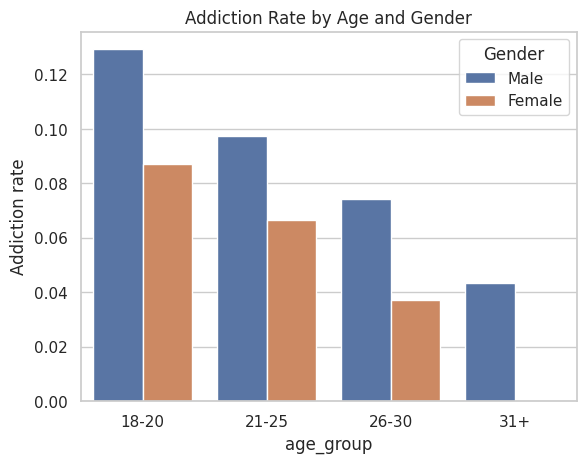

In [279]:
sns.barplot(x='age_group', y='is_addicted', hue='Gender',data=df[df['Gender'] != 'Other'], errorbar=None)
plt.title('Addiction Rate by Age and Gender')
plt.ylabel('Addiction rate')
plt.show()

In [280]:
df.groupby(['age_group', 'Gender'], observed=False)['is_addicted'].mean() * 100

age_group  Gender
18-20      Female     8.709677
           Male      12.921847
           Other     32.000000
21-25      Female     6.644518
           Male       9.750786
           Other     33.333333
26-30      Female     3.703704
           Male       7.407407
           Other      0.000000
31+        Female     0.000000
           Male       4.347826
           Other     66.666667
Name: is_addicted, dtype: float64

In [281]:
df['Gender'].value_counts()

,count
Gender,
Male,11933
Female,688
Other,47


**Q1 Which age groups are most addicted, and does it differ between genders?**

 **answer**:
The most addicted group is **males aged 18-20** (about 13%). For both males and females, addiction goes down as age goes up. Males are more addicted than females in every age group.
I ignored the "Other" gender results because there are only around 47 people in that group, so the percentages jump a lot and are not reliable.

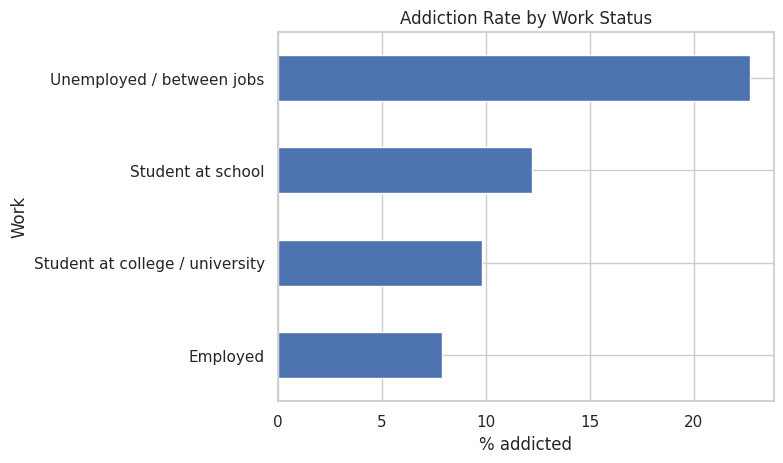

In [282]:
work_s=(df.groupby('Work')['is_addicted'].mean() * 100).sort_values()
work_s.plot(kind='barh')
plt.title('Addiction Rate by Work Status')
plt.xlabel('% addicted')
plt.show()


In [283]:
work_s

,is_addicted
Work,
Employed,7.878555
Student at college / university,9.813850
Student at school,12.231969
Unemployed / between jobs,22.709777


**Q2 Does addiction differ by work status level?**

**answer:**

 **Unemployed players have the highest addiction rate (about 23%)**, which is almost three times the employed players (about 8%). School students (12%) are also higher than university students (10%).
I can't tell which one causes the other. Maybe unemployed people have more free time to play, or maybe gaming too much made it harder for them to keep a job.

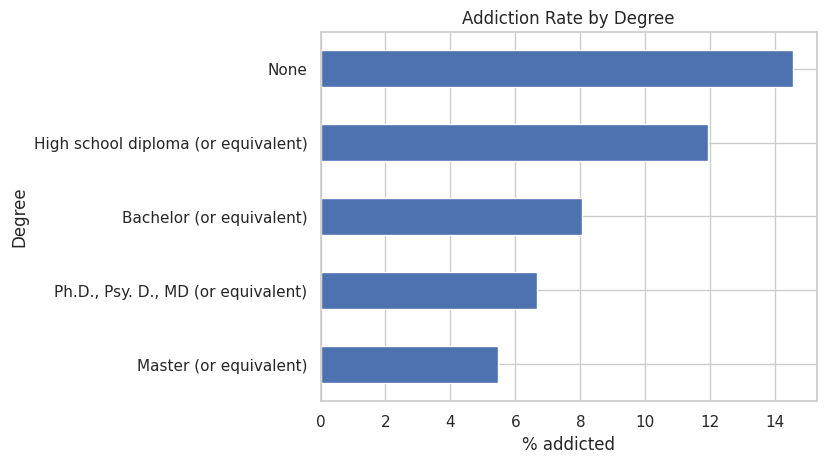

In [284]:
degree = (df.groupby('Degree')['is_addicted'].mean() * 100).sort_values()
degree.plot(kind='barh')
plt.title('Addiction Rate by Degree')
plt.xlabel('% addicted')
plt.show()

In [285]:
degree

,is_addicted
Degree,
Master (or equivalent),5.471698
"Ph.D., Psy. D., MD (or equivalent)",6.666667
Bachelor (or equivalent),8.053167
High school diploma (or equivalent),11.914841
None,14.540466


**Q2 Does addiction differ by education level?**

**answer:**
The lower the degree, the higher the addiction rate. People with **no degree (None)** have the highest rate (about 15%), then high school (12%), bachelor (8%) and master (5%).
But I think age plays a role here too, because people with higher degrees are usually older, and older players are less addicted (from Q1).

In [286]:
impact = pd.crosstab(df['Anxiety_Impact'], df['is_addicted'], normalize='columns') * 100
order = ['Not difficult at all', 'Somewhat difficult', 'Very difficult', 'Extremely difficult']
impact = impact.loc[order]
impact

is_addicted,False,True
Anxiety_Impact,,
Not difficult at all,51.945283,46.028369
Somewhat difficult,38.195061,37.163121
Very difficult,7.274827,10.354610
Extremely difficult,2.584829,6.453901


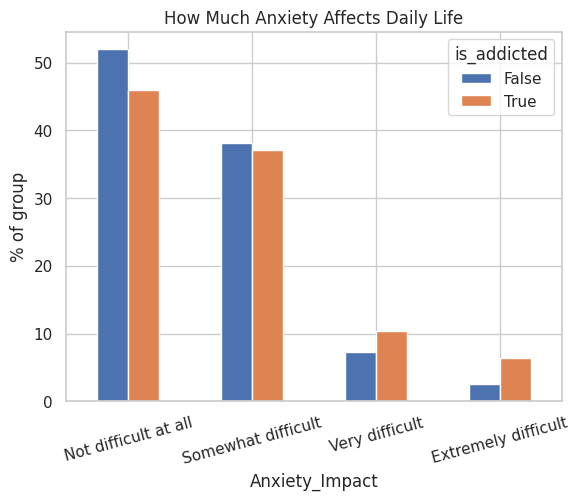

In [287]:
impact.plot(kind='bar')
plt.title('How Much Anxiety Affects Daily Life')
plt.ylabel('% of group')
plt.xticks(rotation=15)
plt.show()


Addicted players who said anxiety makes their life **extremely difficult** are more than double the non-addicted players (6.5% vs 2.6%). So for the addicted players, anxiety affects their work, studies and relationships more.

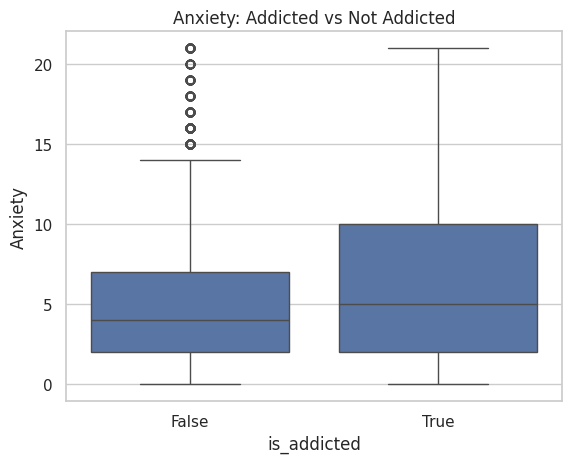

In [288]:
sns.boxplot(x='is_addicted', y='Anxiety', data=df)
plt.title('Anxiety: Addicted vs Not Addicted')
plt.show()

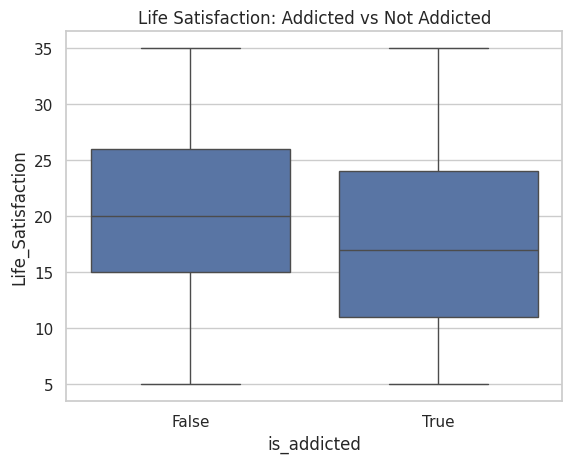

In [289]:
sns.boxplot(x='is_addicted', y='Life_Satisfaction', data=df)
plt.title('Life Satisfaction: Addicted vs Not Addicted')
plt.show()

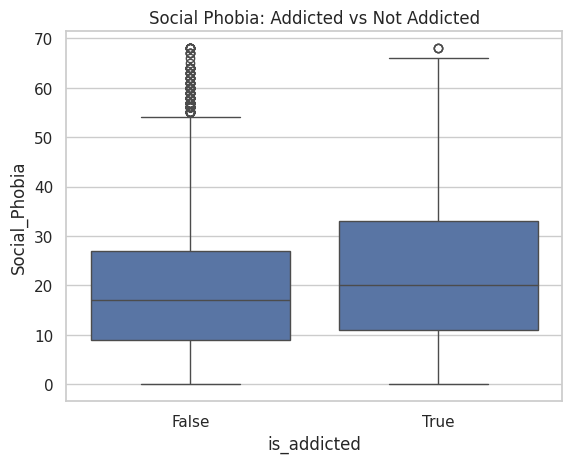

In [290]:
sns.boxplot(x='is_addicted', y='Social_Phobia', data=df)
plt.title('Social Phobia: Addicted vs Not Addicted')
plt.show()

In [291]:
df.groupby('is_addicted')[['Anxiety', 'Life_Satisfaction', 'Social_Phobia']].median()

,Anxiety,Life_Satisfaction,Social_Phobia
is_addicted,,,
False,4.0,20.0,17.0
True,5.0,17.0,20.0


In [292]:
df.groupby('is_addicted')[['Anxiety', 'Life_Satisfaction', 'Social_Phobia']].mean()

,Anxiety,Life_Satisfaction,Social_Phobia
is_addicted,,,
False,5.033132,20.066619,19.449636
True,6.465957,17.723404,22.718440


**Q3 Do addicted gamers have higher anxiety, lower life satisfaction and higher social phobia?**

**answer:**
- **Anxiety:** median is 5 for addicted vs 4 for non-addicted.
- **Life satisfaction:** median is 17 for addicted vs 20 for non-addicted.
- **Social phobia:** median is 20 for addicted vs 17 for non-addicted.

All three show the same thing: addicted players are doing worse mentally. But the boxes overlap a lot, so the difference is not huge. There are many addicted players who are fine, and many non-addicted players who are not.

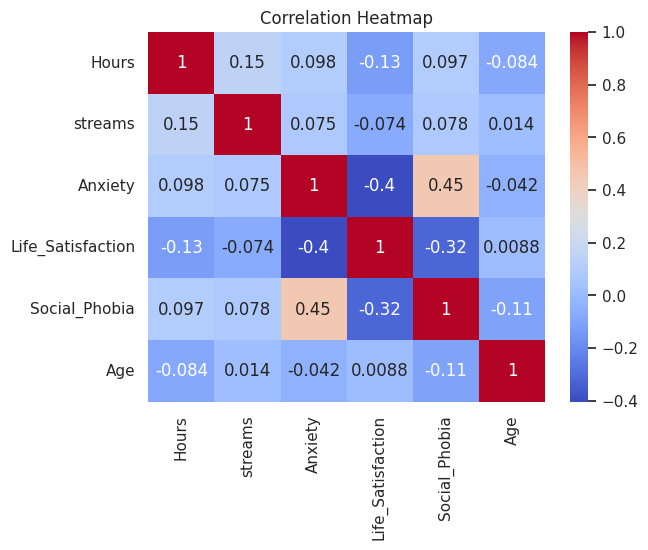

In [293]:
numeric_cols = ['Hours', 'streams', 'Anxiety', 'Life_Satisfaction', 'Social_Phobia', 'Age']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Q4 Is the relationship between gaming hours and mental health strong?**

**answer:**

The correlation between Hours and the mental health scores is weak (around 0.1). This surprised me at first because the boxplots showed a clear difference.
I think the reason is that most people play 10-30 hours and there is not much difference between them. The difference only shows at the extreme (40+ hours).
The strongest correlations are actually between the mental health scores themselves: anxiety and social phobia (0.45), and anxiety and life satisfaction (-0.40). People with high anxiety usually also have higher social phobia and lower life satisfaction.

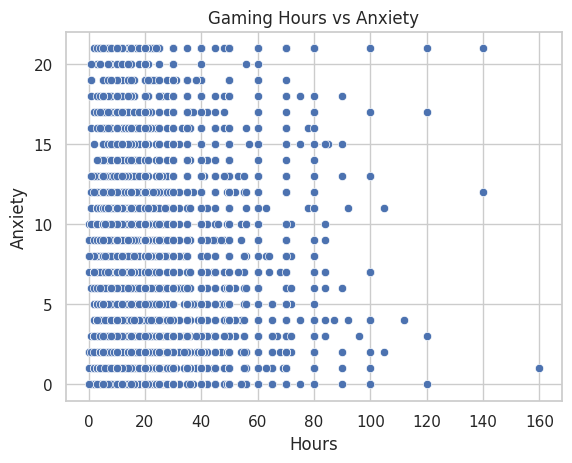

In [294]:
sns.scatterplot(x='Hours', y='Anxiety', data=df)
plt.title('Gaming Hours vs Anxiety')
plt.show()


The points are spread everywhere and there is no clear line, which confirms the weak correlation. Also, correlation does not mean causation. I can't say gaming causes anxiety, because it could be the opposite: anxious people might play more to escape.

In [295]:
df.groupby('whyplay')[['Hours', 'Anxiety', 'Life_Satisfaction']].mean().sort_values('Anxiety')

,Hours,Anxiety,Life_Satisfaction
whyplay,,,
having fun,19.067743,4.590157,20.690974
improving,23.064795,5.252052,19.618143
other,24.699507,5.586207,19.480296
all of the above,24.187500,5.687500,19.875000
winning,24.201741,6.165387,18.323605
relaxing,18.815359,6.279412,18.906863


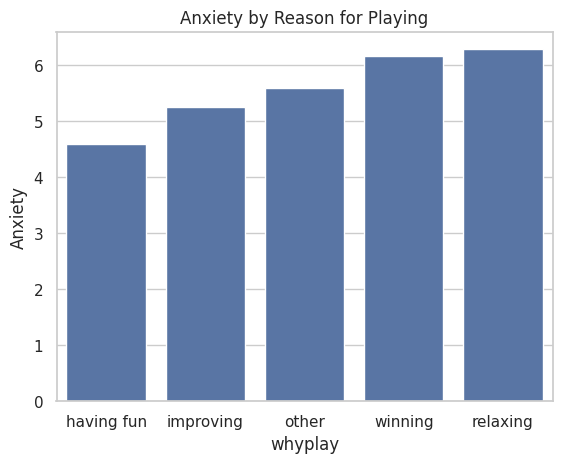

In [296]:
sns.barplot(x='whyplay', y='Anxiety', data=df, errorbar=None,
            order=['having fun', 'improving', 'other', 'winning', 'relaxing'])
plt.title('Anxiety by Reason for Playing')
plt.show()

**Q5 Does the reason for playing (whyplay) affect anxiety?**

 **answer:**

This was the most interesting result for me. Players who play **for fun** have the lowest anxiety (4.6). Players who play **to relax** have the highest anxiety (6.3), even though they play the **fewest hours** (18.8 per week).
So the reason for playing seems to matter more than the number of hours. My guess is that people who play to relax are using games to escape stress.

In [297]:
df.groupby('Playstyle')[['Anxiety', 'Life_Satisfaction', 'Social_Phobia']].mean()

,Anxiety,Life_Satisfaction,Social_Phobia
Playstyle,,,
Offline (same room),4.086957,22.652174,17.326087
Online friends,5.452324,18.901042,20.572516
Real friends,4.758252,20.951727,18.793932
Singleplayer,5.765278,18.601389,22.050000
Strangers,5.540422,19.007467,20.428939
other,4.893238,20.124555,18.256228


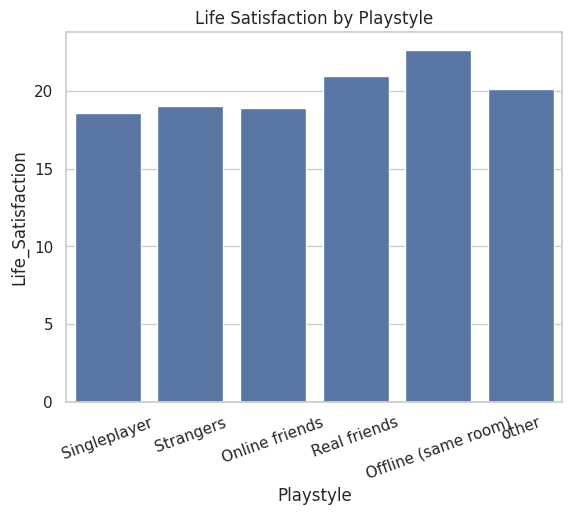

In [298]:
sns.barplot(x='Playstyle', y='Life_Satisfaction', data=df, errorbar=None)
plt.title('Life Satisfaction by Playstyle')
plt.xticks(rotation=20)
plt.show()

**Q6 Is playing with friends better than playing alone?**

 **answer:**

Players who play with **real life friends** have higher life satisfaction (21.0) than players who play alone (18.6) or with strangers (19.0). Singleplayer players had the worst scores in all three: highest anxiety, lowest life satisfaction and highest social phobia.
The "Offline (same room)" group looks the best (22.7), but it only has 46 people, so I don't rely on it.

In [299]:
df.groupby('earnings')['is_addicted'].agg(['mean', 'count'])

,mean,count
earnings,,
i earn a living by playing this game,0.533333,45
i play for fun,0.094788,11415
"i play mostly for fun but earn a little on the side (tournament winnings, streaming, etc)",0.252999,917
other,0.247423,291



More than half of the players who earn a living from gaming play 40+ hours. These people are working, not addicted, so my definition of addiction (40+ hours) counts them by mistake. But there are only 45 of them out of 12,668, so they don't change the overall results. I mention this in the limitations.

## Insights Summary

**What I found:**
- About **11%** of the players play 40 hours or more per week, which is what I defined as addicted.
- The most addicted group is **young males (18-20)**, and addiction goes down with age.
- **Unemployed** players and players with **no degree** have the highest addiction rates.
- Addicted players have **higher anxiety, lower life satisfaction and higher social phobia**, and more of them say anxiety makes their daily life difficult.
- But the relationship between hours and mental health is **weak** (r about 0.1).
- **Why** and **with who** people play matters more: playing for fun and with real friends goes with better mental health, while playing to relax or playing alone goes with worse mental health.

**Outliers:**
I removed 2 players who were clearly joking (8000 and 420 hours a week, with answers like "for my ear"). I kept the high but realistic values because they are the addicted players I wanted to study.

**Conclusion:**
The original paper asked "Are gamers sad and isolated?". From my analysis, the answer is **not all of them**. Gamers who play a lot, play alone, or play to escape stress have worse mental health, but gamers who play for fun with their friends are doing fine. This matches what Sauter et al. (2021) found: social context and motives predict mental health better than time played.

**Limitations:**
- I defined addiction using hours only, which is not a medical diagnosis. It also counts players who earn a living from gaming as addicted, even though gaming is their job, not an addiction.
- The sample is not balanced: 94% male, 98% PC, mostly from Reddit and League of Legends players.
- **Hours** only counts the player's main game, not all games.
- Everyone is 18+, so teenagers are not included.
- The survey did not include game genres like horror, so I couldn't study game type.
- It is a self-reported survey, and I can only show relationships, not causes.

**Recommendations for future analysis:**
- Use a real gaming addiction scale instead of hours only.
- Collect more female, console and mobile players.
- Compare different game genres (like horror vs competitive games).